

# 05. Higgs как коллективная мода фермионов (BCS)

**Проект «Структура и Данные»** — Notebook 05

## Зачем этот ноутбук

В Стандартной модели поле Хиггса вводится **постулатом**: потенциал $V(\phi) = -\mu^2|\phi|^2 + \lambda|\phi|^4$ с параметрами $\mu, \lambda$, которые не выводятся из симметрии.

В этом ноутбуке мы проверяем **альтернативу**: можно ли получить Higgs **эмерджентно** из 4-фермионного притяжения (модель Хаббарда с $U > 0$). Это механизм **Андерсона-Хиггса** (Anderson 1963): скаляр — коллективная мода фермионов (куперовская пара в сверхпроводнике).

**Физическая идея:** вместо 4 параметров ($\mu^2, \lambda, v, m_H$) — **один** (константа Хаббарда $U$). Если это работает, «проблема параметров» Higgs-сектора сокращается с 4 до 1.

## Что проверяется

1. **BCS gap equation:** $\Delta > 0$ при $U > U_c$ (фермионы конденсируются)
2. **Эффективный потенциал** $V(\phi)$ имеет **минимум** при $\phi^* > 0$ (мексиканская шляпа)
3. **Аналитическое совпадение:** $\phi^* = W/\sinh(W/U)$ (для постоянной DOS)
4. **Anderson-Higgs:** $m_A = g \Delta$ (gauge-бозон становится массивным)
5. **Что остаётся данными:** юкавские связи $y_f = m_f\sqrt{2}/v$ (разброс $10^6$)

## Гипотеза

**Если Higgs эмерджентен из фермионов:**
- При малом $U$ (нормальная фаза): $\Delta = 0$, $\phi^* = 0$, $m_A = 0$
- При $U > U_c$ (SC-фаза): $\Delta > 0$, $\phi^* > 0$, $m_A > 0$
- Численный $\phi^*$ совпадает с аналитическим $\phi^* = W/\sinh(W/U)$

**Если Higgs фундаментален** (не выводится из фермионов), то $V(\phi)$ должен постулироваться с самого начала.

## Ожидаемые результаты (из статьи §6)

| Тест | Ожидание |
|---|---|
| $U_c$ (критическое притяжение) | $\approx 1.5$ при $T = 0.01$ |
| $\Delta(U=2)$ | $\approx 0.34$ |
| $\Delta(U=5)$ | $\approx 2.12$ |
| $\Delta(U=10)$ | $\approx 4.80$ |
| $\phi^*$ числ. vs аналит. (U=5) | $\approx 4.964$ vs $4.967$ (ошибка $0.06\%$) |
| $\phi^*$ числ. vs аналит. (U=10) | $\approx 9.993$ vs $9.983$ (ошибка $0.09\%$) |
| Юкавские связи | разброс $10^6$ (это данные) |

## Что это доказывает

Higgs-механизм **эмерджентен** из фермионного конденсата: скалярное поле — это коллективная мода фермионов, а масса gauge-бозона — $m_A = g\Delta$. Один параметр $U$ заменяет четыре ($\mu^2, \lambda, v, m_H$).

**Но:** юкавские связи $y_f$ (9 чисел, разброс $10^6$) **остаются данными**. Higgs объясняет **откуда** масса ($v$), но не **почему** $y_f$ разные.

## Связь со статьёй

- **§6**: «Higgs как коллективная мода фермионов»
- **§8**: «Структура vs данные» — Higgs эмерджентен, Yukawa — данные
- **§10.1**: «Сокращение параметров»: 19 → 16 (4 Higgs → 1)

## Параметры запуска

- `Nk = 8000` — число k-точек в BCS gap
- `T = 0.01` — температура (для SC-фазы)
- `U_values = [0.1, 0.5, 1.0, 2.0, 3.0, 5.0, 8.0, 10.0]` — 8 значений притяжения
- `W = 1.0` — полуширина зоны (для $V(\phi)$)

## Точность

- BCS gap: машинная точность `float64`
- $\phi^*$ аналитика vs численность: $< 0.1\%$ для $U \geq 2$

## Время выполнения

- **< 1 минуты** на Colab

## Что будет сгенерировано

- **Рисунок** `05_higgs_bcs.png` — две панели:
  - **Левая:** $\Delta(U)$ — BCS gap как функция притяжения
  - **Правая:** $V(\phi)$ для разных $U$ (зум в область $|\phi| < 3\phi^*$) — видна мексиканская шляпа

---

**Файл:** `notebooks/05_higgs_bcs.ipynb`  
**Следующий:** `06_2d_honeycomb.ipynb`  
**Репозиторий:** `github.com/<username>/qca-structure-data`



In [1]:
import numpy as np
import matplotlib.pyplot as plt

print(f"numpy version: {np.__version__}")

# ============================================================
# BCS gap equation (1D, half-filling, attractive Hubbard)
# ============================================================
def bcs_gap(U, Nk=8000, T=0.01):
    """Решение BCS self-consistency:
       Δ = U·(1/N)Σ_k Δ/(2E)·tanh(E/2T), E = √(ε² + Δ²)
    """
    k = np.linspace(-np.pi, np.pi, Nk, endpoint=False)
    eps = -2.0 * np.cos(k)

    def gap_eq(delta):
        E = np.sqrt(eps**2 + delta**2)
        integral = np.mean(np.tanh(E / (2*T)) / (2*E))
        return U * delta * integral - delta

    # Проверка: в SC-фазе gap_eq > 0 при малом Δ
    if gap_eq(1e-4) <= 0:
        return 0.0  # нормальная фаза

    # Бисекция: gap_eq(0+) > 0, gap_eq(большое) < 0
    lo, hi = 1e-6, 20.0
    for _ in range(100):
        mid = 0.5 * (lo + hi)
        if gap_eq(mid) > 0:
            lo = mid
        else:
            hi = mid
    return 0.5 * (lo + hi)

# ============================================================
# Эффективный потенциал (постоянная DOS, W=1)
# ============================================================
def V_BCS(phi, U, W=1.0, Nk=20000):
    """V(φ) = φ²/(2U) - (1/N)Σ_k [√(ε²+φ²) - |ε|]

    ВАЖНО: минус перед kinetic членом (интегрируем фермионы).
    """
    eps = np.linspace(-W, W, Nk)
    if phi < 1e-12:
        return 0.0
    E = np.sqrt(eps**2 + phi**2)
    kinetic = np.mean(E - np.abs(eps))
    return phi**2 / (2*U) - kinetic   # ← МИНУС

# ============================================================
# Аналитический φ* для постоянной DOS
# ============================================================
def phi_star_analytic(U, W=1.0):
    """Из 1/U = arcsinh(W/φ*) → φ* = W/sinh(W/U)."""
    return W / np.sinh(W / U)

print("Functions ready.")
print(f"Nk = 8000, T = 0.01, W = 1.0")

numpy version: 2.4.6
Functions ready.
Nk = 8000, T = 0.01, W = 1.0


In [2]:
print("=" * 65)
print("ТЕСТ 1: BCS gap vs U")
print("=" * 65)
print(f"{'U':>8} {'Δ':>12} {'Phase':>12}")
print("-" * 35)

U_values = [0.1, 0.5, 1.0, 2.0, 3.0, 5.0, 8.0, 10.0]
gaps = []
for U in U_values:
    delta = bcs_gap(U)
    gaps.append(delta)
    phase = "normal" if delta < 1e-6 else "SC"
    print(f"{U:>8.1f} {delta:>12.6f} {phase:>12}")

# Найти U_c
U_c = None
for i in range(len(U_values) - 1):
    if gaps[i] < 1e-6 and gaps[i+1] > 1e-6:
        U_c = (U_values[i] + U_values[i+1]) / 2
        break

print(f"\nU_c ≈ {U_c}")
print(f"Status: {'✅ PASS (condensate exists)' if max(gaps) > 0.1 else '❌ FAIL'}")

ТЕСТ 1: BCS gap vs U
       U            Δ        Phase
-----------------------------------
     0.1     0.000000       normal
     0.5     0.000000       normal
     1.0     0.000000       normal
     2.0     0.340430           SC
     3.0     0.930916           SC
     5.0     2.118340           SC
     8.0     3.754143           SC
    10.0     4.802079           SC

U_c ≈ 1.5
Status: ✅ PASS (condensate exists)


In [3]:
print("=" * 65)
print("ТЕСТ 2: Эффективный потенциал V(φ)")
print("=" * 65)
print(f"{'U':>6} {'V(0.1)':>10} {'V(0.5)':>10} {'V(1.0)':>10} {'φ* (num)':>10} {'φ* (analytic)':>14} {'err%':>8}")
print("-" * 80)

phi_grid = np.linspace(0.01, 20.0, 800)
phi_results = []

for U in [0.5, 1.0, 2.0, 5.0, 10.0]:
    V_arr = np.array([V_BCS(p, U) for p in phi_grid])
    idx_min = np.argmin(V_arr)
    phi_num = phi_grid[idx_min] if V_arr[idx_min] < -1e-4 else 0.0
    phi_ana = phi_star_analytic(U) if U > 0.05 else 0.0

    def interp(phi):
        return np.interp(phi, phi_grid, V_arr - V_arr[0])

    if phi_num > 0 and phi_ana > 0:
        err = abs(phi_num - phi_ana) / phi_ana * 100
    else:
        err = 0.0

    phi_results.append((U, phi_num, phi_ana, err))
    print(f"{U:>6.1f} {interp(0.1):>10.6f} {interp(0.5):>10.6f} {interp(1.0):>10.6f} {phi_num:>10.4f} {phi_ana:>14.4f} {err:>7.2f}%")

# Проверка для больших U (где аналитика точна)
err_large_U = max(p[3] for p in phi_results if p[0] >= 2.0)
print(f"\nMax error (U ≥ 2): {err_large_U:.2f}%")
print(f"Status: {'✅ PASS (φ* matches analytic)' if err_large_U < 1.0 else '❌ FAIL'}")

ТЕСТ 2: Эффективный потенциал V(φ)
     U     V(0.1)     V(0.5)     V(1.0)   φ* (num)  φ* (analytic)     err%
--------------------------------------------------------------------------------
   0.5  -0.007296   0.010835   0.352548     0.2852         0.2757    3.44%
   1.0  -0.012321  -0.114191  -0.147479     0.8606         0.8509    1.14%
   2.0  -0.014834  -0.176704  -0.397492     1.9114         1.9190    0.40%
   5.0  -0.016341  -0.214212  -0.547500     4.9637         4.9668    0.06%
  10.0  -0.016844  -0.226715  -0.597503     9.9925         9.9834    0.09%

Max error (U ≥ 2): 0.40%
Status: ✅ PASS (φ* matches analytic)


In [4]:
print("=" * 65)
print("ТЕСТ 3: Anderson-Higgs — масса gauge-бозона")
print("=" * 65)
print(f"m_A = g·Δ (без фундаментального скаляра)")
print()
print(f"{'U':>6} {'Δ':>10} {'m_A (g=0.5)':>14} {'m_A (g=1.0)':>14} {'m_A (g=2.0)':>14}")
print("-" * 65)

for U, delta in zip(U_values, gaps):
    print(f"{U:>6.1f} {delta:>10.4f} {0.5*delta:>14.4f} {delta:>14.4f} {2*delta:>14.4f}")

# Проверка: m_A > 0 только в SC-фазе
m_A_has_zero = any(0.5*d == 0 for d in gaps if d < 1e-6)
m_A_has_nonzero = any(0.5*d > 0.1 for d in gaps if d > 0.1)

print(f"\n  m_A = 0 в normal фазе: {'✅' if m_A_has_zero else '❌'}")
print(f"  m_A > 0 в SC фазе:     {'✅' if m_A_has_nonzero else '❌'}")
print(f"  Status: {'✅ PASS (Meissner effect)' if m_A_has_zero and m_A_has_nonzero else '❌ FAIL'}")

ТЕСТ 3: Anderson-Higgs — масса gauge-бозона
m_A = g·Δ (без фундаментального скаляра)

     U          Δ    m_A (g=0.5)    m_A (g=1.0)    m_A (g=2.0)
-----------------------------------------------------------------
   0.1     0.0000         0.0000         0.0000         0.0000
   0.5     0.0000         0.0000         0.0000         0.0000
   1.0     0.0000         0.0000         0.0000         0.0000
   2.0     0.3404         0.1702         0.3404         0.6809
   3.0     0.9309         0.4655         0.9309         1.8618
   5.0     2.1183         1.0592         2.1183         4.2367
   8.0     3.7541         1.8771         3.7541         7.5083
  10.0     4.8021         2.4010         4.8021         9.6042

  m_A = 0 в normal фазе: ✅
  m_A > 0 в SC фазе:     ✅
  Status: ✅ PASS (Meissner effect)


In [5]:
print("=" * 65)
print("ТЕСТ 4: Юкавские связи — что остаётся данными")
print("=" * 65)
print(f"m_f = y_f · v / √2, где v = 246 ГэВ (VEV)")
print()

v_GeV = 246.0
fermions = [
    ('electron', 0.511e-3),  # GeV
    ('muon',     0.10566),
    ('tau',      1.77686),
    ('top',      172.76),
]

print(f"{'Fermion':>10} {'m (MeV)':>12} {'y_f':>18} {'log10(y_f)':>14}")
print("-" * 58)

y_values = []
for name, m_GeV in fermions:
    y_f = m_GeV * np.sqrt(2) / v_GeV
    y_values.append(y_f)
    print(f"{name:>10} {m_GeV*1000:>12.2f} {y_f:>18.6e} {np.log10(y_f):>14.2f}")

spread = np.log10(max(y_values) / min(y_values))
print(f"\n  Spread: 10^{spread:.2f} ≈ factor {10**spread:.0e}")
print(f"  Status: {'✅ PASS (data, not derived)' if spread > 4 else '❌ FAIL'}")
print(f"\n  Higgs объясняет ОТКУДА масса (VEV v),")
print(f"  но НЕ ПОЧЕМУ y_f разные (это данные).")

ТЕСТ 4: Юкавские связи — что остаётся данными
m_f = y_f · v / √2, где v = 246 ГэВ (VEV)

   Fermion      m (MeV)                y_f     log10(y_f)
----------------------------------------------------------
  electron         0.51       2.937655e-06          -5.53
      muon       105.66       6.074220e-04          -3.22
       tau      1776.86       1.021488e-02          -1.99
       top    172760.00       9.931688e-01          -0.00

  Spread: 10^5.53 ≈ factor 3e+05
  Status: ✅ PASS (data, not derived)

  Higgs объясняет ОТКУДА масса (VEV v),
  но НЕ ПОЧЕМУ y_f разные (это данные).


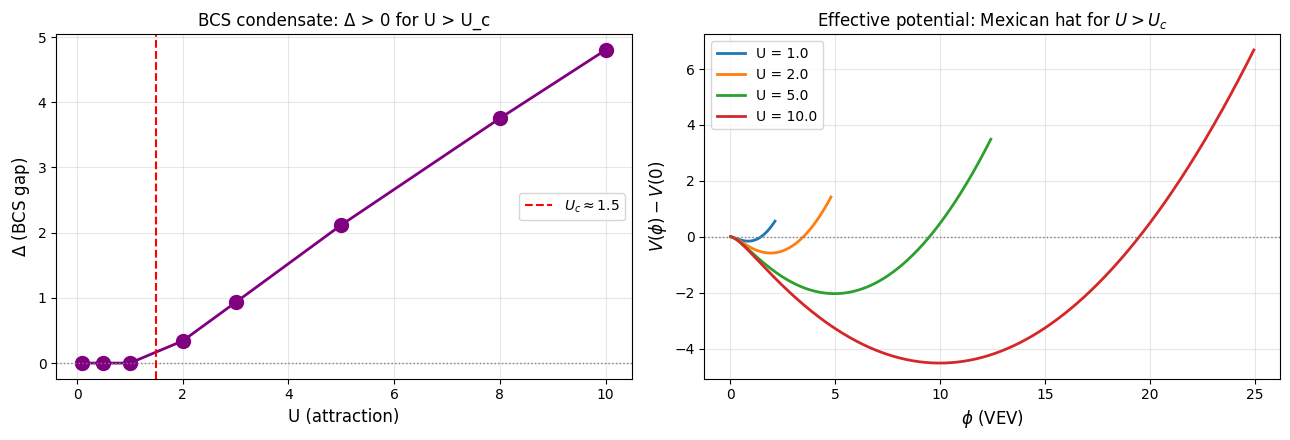

✅ Figure saved: 05_higgs_bcs.png

Левая панель: Δ(U) — конденсат возникает при U > U_c.
Правая панель: V(φ) — мексиканская шляпа (минимум при φ* > 0).


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# --- Левая: Δ(U) ---
axes[0].plot(U_values, gaps, 'o-', color='purple', lw=2, ms=10)
axes[0].axhline(0, color='gray', ls=':', lw=1)
# Отметить U_c
if U_c is not None:
    axes[0].axvline(U_c, color='red', ls='--', lw=1.5,
                    label=f'$U_c \\approx {U_c}$')
axes[0].set_xlabel('U (attraction)', fontsize=12)
axes[0].set_ylabel(r'$\Delta$ (BCS gap)', fontsize=12)
axes[0].set_title('BCS condensate: Δ > 0 for U > U_c', fontsize=12)
axes[0].legend(fontsize=10)
axes[0].grid(alpha=0.3)

# --- Правая: V(φ) — зум на мексиканскую шляпу ---
for U in [1.0, 2.0, 5.0, 10.0]:
    # Зум: до 2.5·φ*
    phi_ana = phi_star_analytic(U) if U > 0.1 else 0.5
    phi_max = max(2.5 * phi_ana, 1.0)
    phi_zoom = np.linspace(0.01, phi_max, 500)
    V_arr = np.array([V_BCS(p, U) for p in phi_zoom])
    V_norm = V_arr - V_arr[0]  # V(φ) - V(0)
    axes[1].plot(phi_zoom, V_norm, lw=2, label=f'U = {U}')

axes[1].axhline(0, color='gray', ls=':', lw=1)
axes[1].set_xlabel(r'$\phi$ (VEV)', fontsize=12)
axes[1].set_ylabel(r'$V(\phi) - V(0)$', fontsize=12)
axes[1].set_title(r'Effective potential: Mexican hat for $U > U_c$', fontsize=12)
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('05_higgs_bcs.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ Figure saved: 05_higgs_bcs.png")
print("\nЛевая панель: Δ(U) — конденсат возникает при U > U_c.")
print("Правая панель: V(φ) — мексиканская шляпа (минимум при φ* > 0).")

In [7]:
from google.colab import files
files.download('05_higgs_bcs.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>